In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [4]:

# Set the dataset path
DATA_PATH = "./data"

# Convert images into tensors
transform = transforms.ToTensor()

# Download the training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

# Download the testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 170M/170M [28:35<00:00, 99.4kB/s]


Training images: 50000
Testing images: 10000


In [5]:

from torch.utils.data import DataLoader

# Create training and testing DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 782
Testing batches: 157


In [6]:

# Get one batch of images and labels
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Single image shape:", images[0].shape)


Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
Single image shape: torch.Size([3, 32, 32])


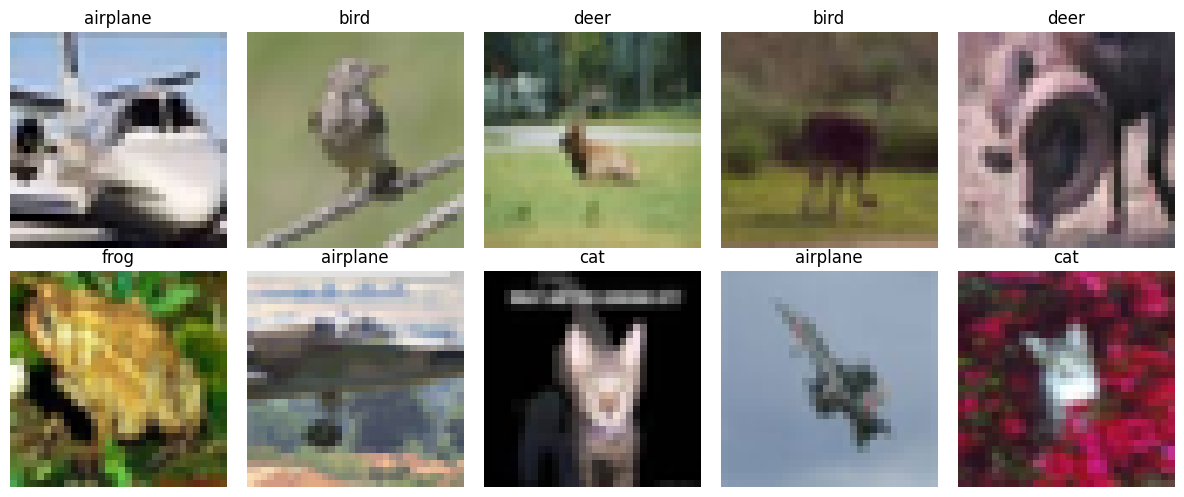

In [7]:

# CIFAR-10 class names
classes = train_dataset.classes

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# CNN baseline model
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32 x 16 x 16

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)   # 64 x 8 x 8
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)  # CIFAR-10 has 10 classes
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

Using device: cuda
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [9]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    total_images = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    return total_loss / total_images


def evaluate_model(model, test_loader, criterion, device):
    model.eval()
    total_loss = 0
    total_images = 0
    correct = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()

    test_loss = total_loss / total_images
    accuracy = 100 * correct / total_images
    return test_loss, accuracy

In [10]:
epochs = 5

history = {
    "train_loss": [],
    "test_loss": [],
    "test_accuracy": []
}

for epoch in range(epochs):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    test_loss, test_accuracy = evaluate_model(
        model, test_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

Epoch [1/5] | Train Loss: 1.4827 | Test Loss: 1.2280 | Test Accuracy: 56.18%
Epoch [2/5] | Train Loss: 1.1221 | Test Loss: 1.0562 | Test Accuracy: 62.19%
Epoch [3/5] | Train Loss: 0.9594 | Test Loss: 1.0079 | Test Accuracy: 64.91%
Epoch [4/5] | Train Loss: 0.8677 | Test Loss: 0.9122 | Test Accuracy: 68.33%
Epoch [5/5] | Train Loss: 0.7902 | Test Loss: 0.9026 | Test Accuracy: 68.96%


In [11]:
import pandas as pd

results_table = pd.DataFrame({
  "Epoch": range(1, len(history["train_loss"]) + 1),
    "Training Loss": history["train_loss"],
    "Test Loss": history["test_loss"],
    "Test Accuracy": history["test_accuracy"]
})

display(results_table.style
    .hide(axis="index")
    .format({
        "Training Loss": "{:.4f}",
        "Test Loss": "{:.4f}",
        "Test Accuracy": "{:.2f}%"
    }))

Epoch,Training Loss,Test Loss,Test Accuracy
1,1.4827,1.2280,56.18%
2,1.1221,1.0562,62.19%
3,0.9594,1.0079,64.91%
4,0.8677,0.9122,68.33%
5,0.7902,0.9026,68.96%


## Data augmentation

In [12]:
import random
import numpy as np
from torch.utils.data import DataLoader

AUG_BATCH_SIZE = 64
AUG_EPOCHS = 5
AUG_SEED = 42

CIFAR_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR_STD = [0.2023, 0.1994, 0.2010]

class GaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        return (tensor + torch.randn_like(tensor) * self.std).clamp(0, 1)

augmentation_configs = {
    "Baseline (No Augmentation)": [],
    "Horizontal Flip": ["flip"],
    "Resized Crop + Flip": ["crop", "flip"],
    "Flip + Rotation": ["flip", "rotation"],
    "Color Jitter + Noise": ["color", "noise"],
    "All Augmentations": ["crop", "flip", "rotation", "color", "noise"],
}

def make_train_transform(selected):
    steps = []

    if "crop" in selected:
        steps.append(
            transforms.RandomResizedCrop(
                32, scale=(0.85, 1.0), ratio=(0.9, 1.1)
            )
        )
    if "flip" in selected:
        steps.append(transforms.RandomHorizontalFlip(p=0.5))
    if "rotation" in selected:
        steps.append(transforms.RandomRotation(10))
    if "color" in selected:
        steps.append(
            transforms.ColorJitter(0.2, 0.2, 0.2, 0.03)
        )

    steps.append(transforms.ToTensor())

    if "noise" in selected:
        steps.append(GaussianNoise(0.03))

    steps.append(transforms.Normalize(CIFAR_MEAN, CIFAR_STD))
    return transforms.Compose(steps)

test_transform_aug = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

print("Ready:", len(augmentation_configs), "augmentation settings")

Ready: 6 augmentation settings


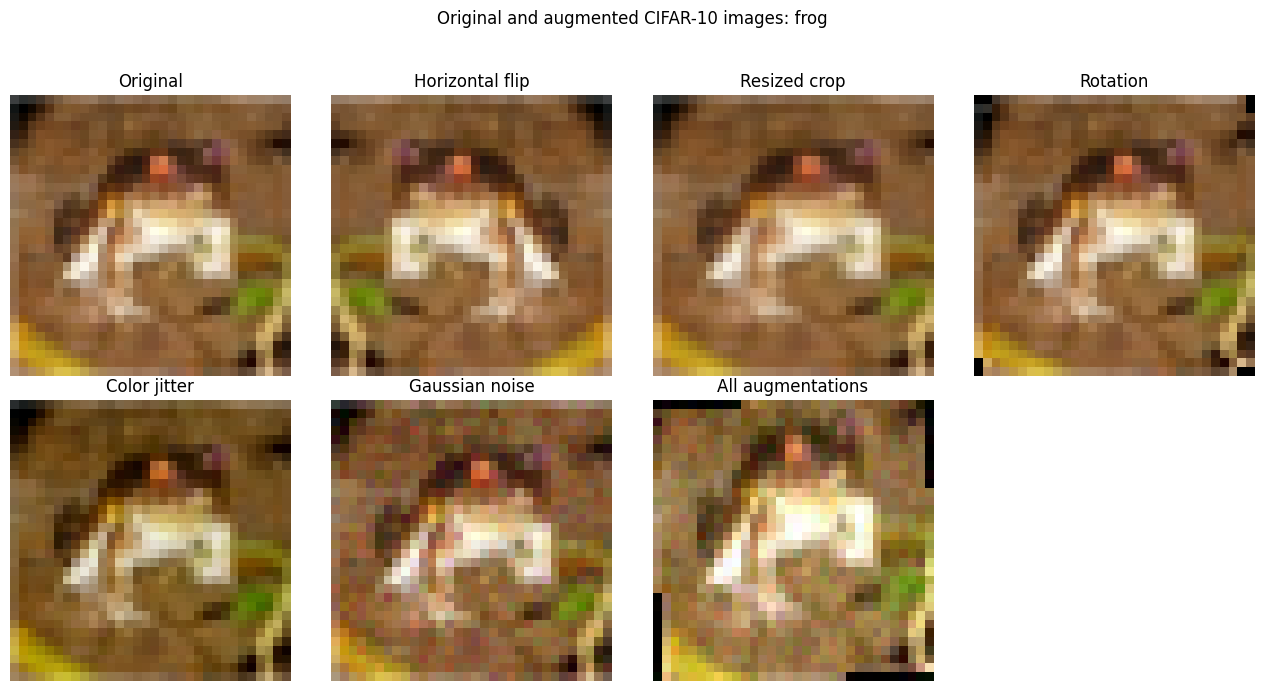

In [13]:
import torch
import matplotlib.pyplot as plt

class GaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        return (tensor + torch.randn_like(tensor) * self.std).clamp(0, 1)

CIFAR_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR_STD = [0.2023, 0.1994, 0.2010]

original_tensor, label = train_dataset[0]
original_pil = transforms.ToPILImage()(original_tensor)

preview_transforms = {
    "Original": transforms.ToTensor(),

    "Horizontal flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor()
    ]),

    "Resized crop": transforms.Compose([
        transforms.RandomResizedCrop(
            32, scale=(0.85, 1.0), ratio=(0.9, 1.1)
        ),
        transforms.ToTensor()
    ]),

    "Rotation": transforms.Compose([
        transforms.RandomRotation(10),
        transforms.ToTensor()
    ]),

    "Color jitter": transforms.Compose([
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
        transforms.ToTensor()
    ]),

    "Gaussian noise": transforms.Compose([
        transforms.ToTensor(),
        GaussianNoise(0.03)
    ]),

    "All augmentations": transforms.Compose([
        transforms.RandomResizedCrop(32, scale=(0.85, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
        transforms.ToTensor(),
        GaussianNoise(0.03),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
    ]),
}

torch.manual_seed(AUG_SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))

for ax, (name, transform_fn) in zip(axes.flat, preview_transforms.items()):
    image = transform_fn(original_pil)

    if name == "All augmentations":
        mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
        std = torch.tensor(CIFAR_STD).view(3, 1, 1)
        image = image * std + mean

    ax.imshow(image.clamp(0, 1).permute(1, 2, 0))
    ax.set_title(name)
    ax.axis("off")

axes.flat[-1].axis("off")
fig.suptitle(f"Original and augmented CIFAR-10 images: {classes[label]}")
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=2)
plt.savefig("augmentation_examples.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
test_dataset_aug = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform_aug
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=AUG_BATCH_SIZE,
    shuffle=False
)

augmentation_histories = {}

for config_name, selected in augmentation_configs.items():
    random.seed(AUG_SEED)
    np.random.seed(AUG_SEED)
    torch.manual_seed(AUG_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(AUG_SEED)

    train_dataset_aug = torchvision.datasets.CIFAR10(
        root=DATA_PATH,
        train=True,
        download=False,
        transform=make_train_transform(selected)
    )

    train_loader_aug = DataLoader(
        train_dataset_aug,
        batch_size=AUG_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(AUG_SEED)
    )

    experiment_model = BaselineCNN().to(device)
    experiment_criterion = nn.CrossEntropyLoss()
    experiment_optimizer = optim.Adam(
        experiment_model.parameters(), lr=0.001
    )

    experiment_history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": []
    }

    print(f"\n=== {config_name} ===")

    for epoch in range(AUG_EPOCHS):
        train_loss = train_one_epoch(
            experiment_model,
            train_loader_aug,
            experiment_criterion,
            experiment_optimizer,
            device
        )

        test_loss, test_accuracy = evaluate_model(
            experiment_model,
            test_loader_aug,
            experiment_criterion,
            device
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["test_loss"].append(test_loss)
        experiment_history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{AUG_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Test loss: {test_loss:.4f} | "
            f"Test accuracy: {test_accuracy:.2f}%"
        )

    augmentation_histories[config_name] = experiment_history

print("\nAll augmentation experiments completed.")


=== Baseline (No Augmentation) ===
Epoch 1/5 | Train loss: 1.2982 | Test loss: 1.0357 | Test accuracy: 62.97%
Epoch 2/5 | Train loss: 0.9202 | Test loss: 0.8996 | Test accuracy: 68.55%
Epoch 3/5 | Train loss: 0.7598 | Test loss: 0.8649 | Test accuracy: 70.19%
Epoch 4/5 | Train loss: 0.6351 | Test loss: 0.8812 | Test accuracy: 69.93%
Epoch 5/5 | Train loss: 0.5336 | Test loss: 0.8641 | Test accuracy: 71.54%

=== Horizontal Flip ===
Epoch 1/5 | Train loss: 1.2865 | Test loss: 1.0061 | Test accuracy: 64.85%
Epoch 2/5 | Train loss: 0.9299 | Test loss: 0.9038 | Test accuracy: 68.27%
Epoch 3/5 | Train loss: 0.7992 | Test loss: 0.8741 | Test accuracy: 69.71%
Epoch 4/5 | Train loss: 0.7109 | Test loss: 0.7989 | Test accuracy: 72.14%
Epoch 5/5 | Train loss: 0.6406 | Test loss: 0.7594 | Test accuracy: 74.14%

=== Resized Crop + Flip ===
Epoch 1/5 | Train loss: 1.3599 | Test loss: 1.0776 | Test accuracy: 61.91%
Epoch 2/5 | Train loss: 1.0267 | Test loss: 0.9630 | Test accuracy: 66.24%
Epoch 3/5 

In [15]:
rows = []

for config_name, h in augmentation_histories.items():
    rows.append({
        "Augmentation": config_name,
        "Train Loss": h["train_loss"][-1],
        "Test Loss": h["test_loss"][-1],
        "Test Accuracy (%)": h["test_accuracy"][-1],
    })

augmentation_results = pd.DataFrame(rows)
augmentation_results = augmentation_results.sort_values(
    by=["Test Accuracy (%)", "Test Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(augmentation_results.round(4))
augmentation_results.to_csv("augmentation_results.csv", index=False)

best = augmentation_results.iloc[0]
control = augmentation_results[
    augmentation_results["Augmentation"] == "Baseline (No Augmentation)"
].iloc[0]

print(f"Best setting: {best['Augmentation']}")
print(f"Best test accuracy: {best['Test Accuracy (%)']:.2f}%")
print(
    "Difference from no augmentation: "
    f"{best['Test Accuracy (%)'] - control['Test Accuracy (%)']:+.2f} percentage points"
)

,Augmentation,Train Loss,Test Loss,Test Accuracy (%)
0,Horizontal Flip,0.6406,0.7594,74.14
1,Resized Crop + Flip,0.7667,0.7889,73.29
2,Flip + Rotation,0.7653,0.8006,72.26
3,Baseline (No Augmentation),0.5336,0.8641,71.54
4,All Augmentations,0.9406,0.8731,69.97
5,Color Jitter + Noise,0.6308,0.9192,69.57


Best setting: Horizontal Flip
Best test accuracy: 74.14%
Difference from no augmentation: +2.60 percentage points


# CNN Architecture Experiments

In [16]:
##5.3
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Experiment settings
EPOCHS = 10
LEARNING_RATE = 0.001

Using device: cuda


In [17]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [18]:
class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [19]:
class MoreFiltersCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [20]:
def run_experiment(model_class, model_name):

    model = model_class().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": []
    }

    print("\nTraining:", model_name)

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        test_loss, test_accuracy = evaluate_model(
            model,
            test_loader,
            criterion,
            device
        )

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Accuracy: {test_accuracy:.2f}%"
        )

    return model, history

In [21]:
results = {}

baseline_model, results["Baseline CNN"] = run_experiment(
    BaselineCNN,
    "Baseline CNN"
)

deeper_model, results["Deeper CNN"] = run_experiment(
    DeeperCNN,
    "Deeper CNN"
)

filters_model, results["More Filters CNN"] = run_experiment(
    MoreFiltersCNN,
    "More Filters CNN"
)


Training: Baseline CNN
Epoch [1/10] Train Loss: 1.5438 | Test Loss: 1.3131 | Test Accuracy: 52.58%
Epoch [2/10] Train Loss: 1.2123 | Test Loss: 1.1217 | Test Accuracy: 59.97%
Epoch [3/10] Train Loss: 1.0594 | Test Loss: 1.0268 | Test Accuracy: 63.98%
Epoch [4/10] Train Loss: 0.9579 | Test Loss: 0.9518 | Test Accuracy: 66.96%
Epoch [5/10] Train Loss: 0.8734 | Test Loss: 0.9407 | Test Accuracy: 67.58%
Epoch [6/10] Train Loss: 0.8084 | Test Loss: 0.9059 | Test Accuracy: 68.50%
Epoch [7/10] Train Loss: 0.7551 | Test Loss: 0.9091 | Test Accuracy: 68.69%
Epoch [8/10] Train Loss: 0.6979 | Test Loss: 0.8849 | Test Accuracy: 69.35%
Epoch [9/10] Train Loss: 0.6510 | Test Loss: 0.9016 | Test Accuracy: 69.87%
Epoch [10/10] Train Loss: 0.5962 | Test Loss: 0.8691 | Test Accuracy: 70.52%

Training: Deeper CNN
Epoch [1/10] Train Loss: 1.5271 | Test Loss: 1.1906 | Test Accuracy: 57.54%
Epoch [2/10] Train Loss: 1.0590 | Test Loss: 0.9717 | Test Accuracy: 65.78%
Epoch [3/10] Train Loss: 0.8735 | Test Lo

In [22]:
import pandas as pd

comparison = []

for name, history in results.items():

    comparison.append({
        "Architecture": name,
        "Training Loss": history["train_loss"][-1],
        "Test Loss": history["test_loss"][-1],
        "Test Accuracy": history["test_accuracy"][-1]
    })

results_df = pd.DataFrame(comparison)

print(results_df.to_string(index=False))

    Architecture  Training Loss  Test Loss  Test Accuracy
    Baseline CNN       0.596165   0.869138          70.52
      Deeper CNN       0.311527   0.925534          73.75
More Filters CNN       0.369720   0.947600          71.69


In [23]:
best_model_name = results_df.loc[
    results_df["Test Accuracy"].idxmax(),
    "Architecture"
]

print("Best Architecture:", best_model_name)

Best Architecture: Deeper CNN


# Hyperparameter Experiments


In [24]:
from torch.utils.data import DataLoader
import pandas as pd

def run_tuning_experiment(lr, batch_size, epochs, experiment_name):

    train_loader_exp = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader_exp = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model = BaselineCNN().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    train_losses = []
    test_losses = []
    accuracies = []

    print("\nExperiment:", experiment_name)

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            model,
            train_loader_exp,
            criterion,
            optimizer,
            device
        )

        test_loss, accuracy = evaluate_model(
            model,
            test_loader_exp,
            criterion,
            device
        )

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        accuracies.append(accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}%"
        )

    return {
        "Experiment": experiment_name,
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Epochs": epochs,
        "Training Loss": train_losses[-1],
        "Test Loss": test_losses[-1],
        "Test Accuracy": accuracies[-1]
    }

In [25]:
lr_results = []

learning_rates = [0.01, 0.001, 0.0001]

for lr in learning_rates:

    result = run_tuning_experiment(
        lr=lr,
        batch_size=64,
        epochs=10,
        experiment_name=f"Learning Rate {lr}"
    )

    lr_results.append(result)


Experiment: Learning Rate 0.01
Epoch 1/10 | Train Loss: 1.5835 | Test Loss: 1.5289 | Accuracy: 46.17%
Epoch 2/10 | Train Loss: 1.3288 | Test Loss: 1.3406 | Accuracy: 52.18%
Epoch 3/10 | Train Loss: 1.2385 | Test Loss: 1.2546 | Accuracy: 56.06%
Epoch 4/10 | Train Loss: 1.1823 | Test Loss: 1.2355 | Accuracy: 56.96%
Epoch 5/10 | Train Loss: 1.1407 | Test Loss: 1.2906 | Accuracy: 54.47%
Epoch 6/10 | Train Loss: 1.0969 | Test Loss: 1.2416 | Accuracy: 58.08%
Epoch 7/10 | Train Loss: 1.0620 | Test Loss: 1.2362 | Accuracy: 57.81%
Epoch 8/10 | Train Loss: 1.0433 | Test Loss: 1.2877 | Accuracy: 57.00%
Epoch 9/10 | Train Loss: 1.0161 | Test Loss: 1.2268 | Accuracy: 58.24%
Epoch 10/10 | Train Loss: 1.0017 | Test Loss: 1.2955 | Accuracy: 57.14%

Experiment: Learning Rate 0.001
Epoch 1/10 | Train Loss: 1.4975 | Test Loss: 1.2538 | Accuracy: 55.77%
Epoch 2/10 | Train Loss: 1.1305 | Test Loss: 1.0820 | Accuracy: 61.00%
Epoch 3/10 | Train Loss: 0.9818 | Test Loss: 0.9514 | Accuracy: 66.62%
Epoch 4/10 

In [26]:
batch_results = []

batch_sizes = [32, 64, 128]

for batch in batch_sizes:

    result = run_tuning_experiment(
        lr=0.001,
        batch_size=batch,
        epochs=10,
        experiment_name=f"Batch Size {batch}"
    )

    batch_results.append(result)



Experiment: Batch Size 32
Epoch 1/10 | Train Loss: 1.4079 | Test Loss: 1.1367 | Accuracy: 59.32%
Epoch 2/10 | Train Loss: 1.0403 | Test Loss: 0.9724 | Accuracy: 66.16%
Epoch 3/10 | Train Loss: 0.8910 | Test Loss: 0.9422 | Accuracy: 67.12%
Epoch 4/10 | Train Loss: 0.7922 | Test Loss: 0.8978 | Accuracy: 68.74%
Epoch 5/10 | Train Loss: 0.7019 | Test Loss: 0.8768 | Accuracy: 70.03%
Epoch 6/10 | Train Loss: 0.6241 | Test Loss: 0.8936 | Accuracy: 70.25%
Epoch 7/10 | Train Loss: 0.5525 | Test Loss: 0.8975 | Accuracy: 70.80%
Epoch 8/10 | Train Loss: 0.4813 | Test Loss: 0.9363 | Accuracy: 71.03%
Epoch 9/10 | Train Loss: 0.4219 | Test Loss: 0.9718 | Accuracy: 70.47%
Epoch 10/10 | Train Loss: 0.3613 | Test Loss: 1.0678 | Accuracy: 70.49%

Experiment: Batch Size 64
Epoch 1/10 | Train Loss: 1.4713 | Test Loss: 1.2205 | Accuracy: 55.85%
Epoch 2/10 | Train Loss: 1.1005 | Test Loss: 1.0150 | Accuracy: 64.21%
Epoch 3/10 | Train Loss: 0.9476 | Test Loss: 0.9547 | Accuracy: 66.25%
Epoch 4/10 | Train Los

In [27]:
epoch_results = []

epoch_values = [5, 10, 15]

for ep in epoch_values:

    result = run_tuning_experiment(
        lr=0.001,
        batch_size=64,
        epochs=ep,
        experiment_name=f"Epochs {ep}"
    )

    epoch_results.append(result)


Experiment: Epochs 5
Epoch 1/5 | Train Loss: 1.5135 | Test Loss: 1.2379 | Accuracy: 56.21%
Epoch 2/5 | Train Loss: 1.1592 | Test Loss: 1.0656 | Accuracy: 62.52%
Epoch 3/5 | Train Loss: 0.9975 | Test Loss: 1.0517 | Accuracy: 62.64%
Epoch 4/5 | Train Loss: 0.8888 | Test Loss: 0.9130 | Accuracy: 68.04%
Epoch 5/5 | Train Loss: 0.8041 | Test Loss: 0.8888 | Accuracy: 68.98%

Experiment: Epochs 10
Epoch 1/10 | Train Loss: 1.5041 | Test Loss: 1.2639 | Accuracy: 55.06%
Epoch 2/10 | Train Loss: 1.1455 | Test Loss: 1.0662 | Accuracy: 61.79%
Epoch 3/10 | Train Loss: 1.0023 | Test Loss: 1.0214 | Accuracy: 64.00%
Epoch 4/10 | Train Loss: 0.9047 | Test Loss: 0.9236 | Accuracy: 68.14%
Epoch 5/10 | Train Loss: 0.8271 | Test Loss: 0.9209 | Accuracy: 68.12%
Epoch 6/10 | Train Loss: 0.7666 | Test Loss: 0.8857 | Accuracy: 69.34%
Epoch 7/10 | Train Loss: 0.7065 | Test Loss: 0.9312 | Accuracy: 67.64%
Epoch 8/10 | Train Loss: 0.6504 | Test Loss: 0.8777 | Accuracy: 70.32%
Epoch 9/10 | Train Loss: 0.5977 | Tes

In [28]:
all_results = (
    lr_results +
    batch_results +
    epoch_results
)

results_df = pd.DataFrame(all_results)

print(results_df.to_string(index=False))

          Experiment  Learning Rate  Batch Size  Epochs  Training Loss  Test Loss  Test Accuracy
  Learning Rate 0.01         0.0100          64      10       1.001727   1.295452          57.14
 Learning Rate 0.001         0.0010          64      10       0.517934   0.908308          71.17
Learning Rate 0.0001         0.0001          64      10       1.099836   1.109712          61.48
       Batch Size 32         0.0010          32      10       0.361292   1.067756          70.49
       Batch Size 64         0.0010          64      10       0.461221   0.940508          70.13
      Batch Size 128         0.0010         128      10       0.573279   0.868890          71.00
            Epochs 5         0.0010          64       5       0.804068   0.888803          68.98
           Epochs 10         0.0010          64      10       0.549102   0.907217          70.68
           Epochs 15         0.0010          64      15       0.330879   1.147272          69.27


In [29]:
best_lr = max(lr_results, key=lambda x: x["Test Accuracy"])
best_batch = max(batch_results, key=lambda x: x["Test Accuracy"])
best_epochs = max(epoch_results, key=lambda x: x["Test Accuracy"])

print("Best Learning Rate:", best_lr["Learning Rate"])
print("Best Batch Size:", best_batch["Batch Size"])
print("Best Epochs:", best_epochs["Epochs"])

Best Learning Rate: 0.001
Best Batch Size: 128
Best Epochs: 10


## Final Model Training

In [30]:

# Code 1: Final Model Configuration

import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from torch.utils.data import DataLoader

FINAL_SEED = 42

FINAL_LR = float(best_lr["Learning Rate"])
FINAL_BATCH_SIZE = int(best_batch["Batch Size"])
FINAL_EPOCHS = int(best_epochs["Epochs"])

random.seed(FINAL_SEED)
np.random.seed(FINAL_SEED)
torch.manual_seed(FINAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(FINAL_SEED)

# Final training dataset with Horizontal Flip
final_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=make_train_transform(["flip"])
)

# Test dataset without random augmentation
final_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=test_transform_aug
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(FINAL_SEED)
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=False
)

# Final architecture
final_model = DeeperCNN().to(device)

final_criterion = nn.CrossEntropyLoss()

final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=FINAL_LR
)

final_history = {
    "train_loss": [],
    "test_loss": [],
    "test_accuracy": []
}

print("Final Model: DeeperCNN + Horizontal Flip")
print("Optimizer: Adam")
print("Learning Rate:", FINAL_LR)
print("Batch Size:", FINAL_BATCH_SIZE)
print("Epochs:", FINAL_EPOCHS)
print("Device:", device)


Final Model: DeeperCNN + Horizontal Flip
Optimizer: Adam
Learning Rate: 0.001
Batch Size: 128
Epochs: 10
Device: cuda


In [31]:

# Code 2: Final Model Training and Testing

for epoch in range(FINAL_EPOCHS):

    train_loss = train_one_epoch(
        final_model,
        final_train_loader,
        final_criterion,
        final_optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        final_model,
        final_test_loader,
        final_criterion,
        device
    )

    final_history["train_loss"].append(float(train_loss))
    final_history["test_loss"].append(float(test_loss))
    final_history["test_accuracy"].append(float(test_accuracy))

    print(
        f"Epoch {epoch+1}/{FINAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

final_metrics = {
    "training_loss": final_history["train_loss"][-1],
    "test_loss": final_history["test_loss"][-1],
    "test_accuracy_percent": final_history["test_accuracy"][-1],
    "architecture": "DeeperCNN",
    "augmentation": "Horizontal Flip",
    "optimizer": "Adam",
    "learning_rate": FINAL_LR,
    "batch_size": FINAL_BATCH_SIZE,
    "epochs": FINAL_EPOCHS,
    "seed": FINAL_SEED
}

print("\nFINAL MODEL RESULTS")
print(json.dumps(final_metrics, indent=2))


Epoch 1/10 | Train Loss: 1.4257 | Test Loss: 1.0973 | Test Accuracy: 60.59%
Epoch 2/10 | Train Loss: 0.9805 | Test Loss: 0.9103 | Test Accuracy: 68.46%
Epoch 3/10 | Train Loss: 0.8086 | Test Loss: 0.8220 | Test Accuracy: 70.92%
Epoch 4/10 | Train Loss: 0.7030 | Test Loss: 0.7794 | Test Accuracy: 72.46%
Epoch 5/10 | Train Loss: 0.6300 | Test Loss: 0.6980 | Test Accuracy: 75.89%
Epoch 6/10 | Train Loss: 0.5670 | Test Loss: 0.6789 | Test Accuracy: 76.72%
Epoch 7/10 | Train Loss: 0.5128 | Test Loss: 0.6520 | Test Accuracy: 78.00%
Epoch 8/10 | Train Loss: 0.4668 | Test Loss: 0.6700 | Test Accuracy: 77.36%
Epoch 9/10 | Train Loss: 0.4322 | Test Loss: 0.6914 | Test Accuracy: 77.46%
Epoch 10/10 | Train Loss: 0.3941 | Test Loss: 0.6945 | Test Accuracy: 77.78%

FINAL MODEL RESULTS
{
  "training_loss": 0.39408629118919375,
  "test_loss": 0.6944912958145142,
  "test_accuracy_percent": 77.78,
  "architecture": "DeeperCNN",
  "augmentation": "Horizontal Flip",
  "optimizer": "Adam",
  "learning_rate

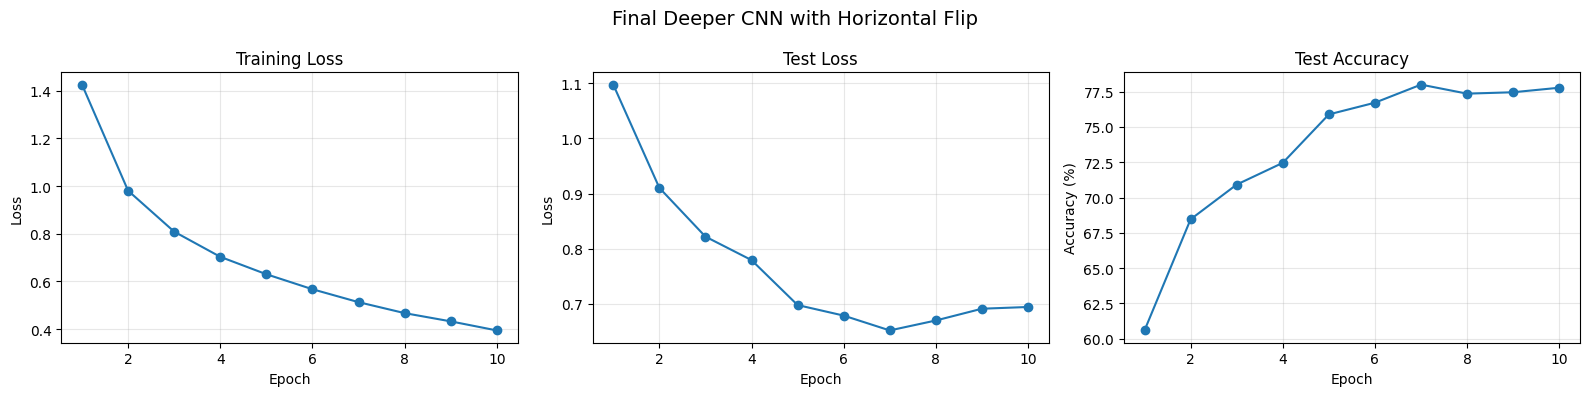

In [32]:

# Code 3: Final Model Performance Graphs

epochs_axis = range(
    1, len(final_history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Training Loss
axes[0].plot(
    epochs_axis,
    final_history["train_loss"],
    marker="o"
)
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)

# Test Loss
axes[1].plot(
    epochs_axis,
    final_history["test_loss"],
    marker="o"
)
axes[1].set_title("Test Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)

# Test Accuracy
axes[2].plot(
    epochs_axis,
    final_history["test_accuracy"],
    marker="o"
)
axes[2].set_title("Test Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].grid(True, alpha=0.3)

fig.suptitle(
    "Final Deeper CNN with Horizontal Flip",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "final_model_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


In [33]:

# Code 4: Final vs Baseline Comparison

baseline_history = results["Baseline CNN"]

baseline_train_loss = baseline_history["train_loss"][-1]
baseline_test_loss = baseline_history["test_loss"][-1]
baseline_accuracy = baseline_history["test_accuracy"][-1]

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Training Loss": baseline_train_loss,
        "Test Loss": baseline_test_loss,
        "Test Accuracy (%)": baseline_accuracy
    },
    {
        "Model": "Final Deeper CNN + Horizontal Flip",
        "Training Loss": final_metrics["training_loss"],
        "Test Loss": final_metrics["test_loss"],
        "Test Accuracy (%)": final_metrics["test_accuracy_percent"]
    }
])

print("\nFinal Model vs Baseline Comparison")
print(comparison_df.to_string(index=False))

accuracy_difference = (
    final_metrics["test_accuracy_percent"]
    - baseline_accuracy
)

print(
    f"\nAccuracy Difference: "
    f"{accuracy_difference:+.2f} percentage points"
)

if accuracy_difference > 0:
    print("Final model achieved higher test accuracy.")
elif accuracy_difference < 0:
    print("Baseline model achieved higher test accuracy.")
else:
    print("Both models achieved equal test accuracy.")



Final Model vs Baseline Comparison
                             Model  Training Loss  Test Loss  Test Accuracy (%)
                      Baseline CNN       0.596165   0.869138              70.52
Final Deeper CNN + Horizontal Flip       0.394086   0.694491              77.78

Accuracy Difference: +7.26 percentage points
Final model achieved higher test accuracy.


In [34]:

# Code 5: Save Final Model and Results

# Save comparison table
comparison_df.to_csv(
    "final_vs_baseline.csv",
    index=False
)

# Save training history
history_df = pd.DataFrame({
    "Epoch": list(range(1, FINAL_EPOCHS + 1)),
    "Training Loss": final_history["train_loss"],
    "Test Loss": final_history["test_loss"],
    "Test Accuracy (%)": final_history["test_accuracy"]
})

history_df.to_csv(
    "final_training_history.csv",
    index=False
)

# Save final metrics
with open("final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

# Save final trained model
torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "model_class": "DeeperCNN",
        "metrics": final_metrics,
        "history": final_history
    },
    "final_cnn_checkpoint.pth"
)

print("Final model and results saved successfully!")
print("Saved files:")
print("- final_cnn_checkpoint.pth")
print("- final_metrics.json")
print("- final_training_history.csv")
print("- final_vs_baseline.csv")
print("- final_model_graphs.png")


Final model and results saved successfully!
Saved files:
- final_cnn_checkpoint.pth
- final_metrics.json
- final_training_history.csv
- final_vs_baseline.csv
- final_model_graphs.png
